In [19]:
import numpy as np
import json
from pathlib import Path
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("robot_wear_dataset")
JOINT_NAMES = ["shoulder_pitch", "shoulder_roll", "elbow_flex", 
               "elbow_rot", "wrist_pitch", "wrist_roll", "gripper"]

# Load all episodes
wear_timeline = []
capacity_timeline = []
pass_fail_timeline = []

for episode_id in range(5000):
    episode_dir = OUTPUT_DIR / f"episode_{episode_id:05d}"
    
    wear_state = np.load(episode_dir / "wear_state.npy")
    with open(episode_dir / "metadata.json") as f:
        metadata = json.load(f)
    
    wear_timeline.append(wear_state)
    capacity_timeline.append(metadata["current_capacity_percent"])
    pass_fail_timeline.append(metadata["num_tests_passed"])

wear_timeline = np.array(wear_timeline)
capacity_timeline = np.array(capacity_timeline)
pass_fail_timeline = np.array(pass_fail_timeline)

print(f"Loaded {len(wear_timeline)} episodes")
print(f"Wear shape: {wear_timeline.shape}")

Loaded 5000 episodes
Wear shape: (5000, 7)


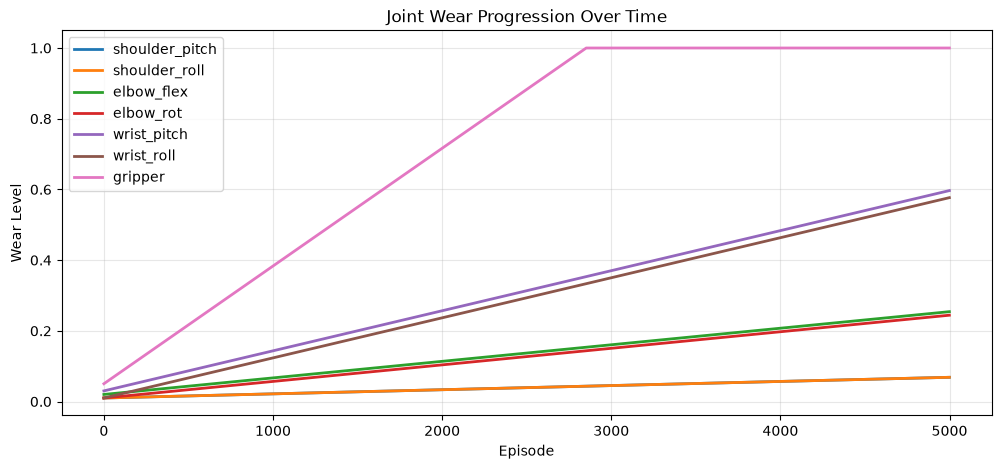

In [20]:
plt.figure(figsize=(12, 5))
for joint_idx in range(7):
    plt.plot(wear_timeline[:, joint_idx], label=JOINT_NAMES[joint_idx], linewidth=2)

plt.xlabel("Episode")
plt.ylabel("Wear Level")
plt.title("Joint Wear Progression Over Time")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

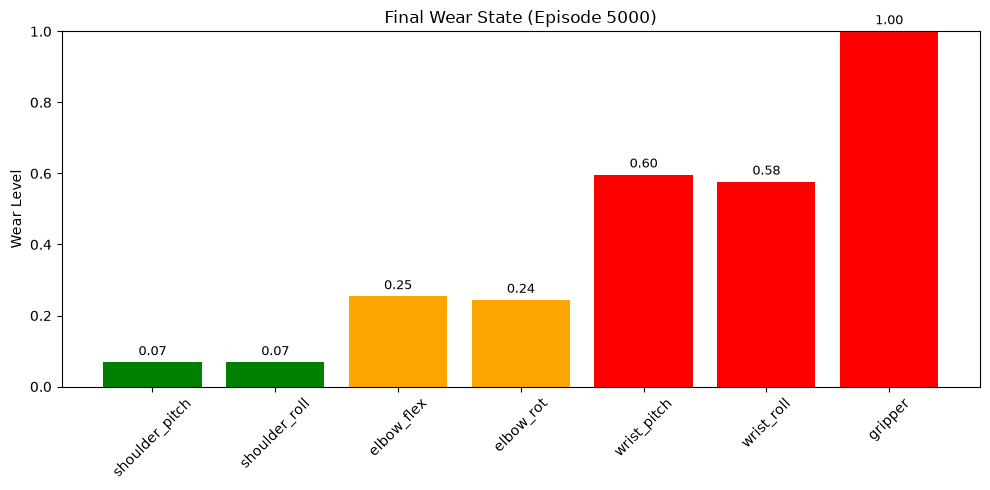

In [21]:
final_wear = wear_timeline[-1]
colors = []
for wear in final_wear:
    if wear < 0.2:
        colors.append("green")
    elif wear < 0.5:
        colors.append("orange")
    else:
        colors.append("red")

plt.figure(figsize=(10, 5))
bars = plt.bar(JOINT_NAMES, final_wear, color=colors)
plt.ylabel("Wear Level")
plt.title("Final Wear State (Episode 5000)")
plt.ylim([0, 1])
for i, (joint, wear) in enumerate(zip(JOINT_NAMES, final_wear)):
    plt.text(i, wear + 0.02, f"{wear:.2f}", ha="center", fontsize=9)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

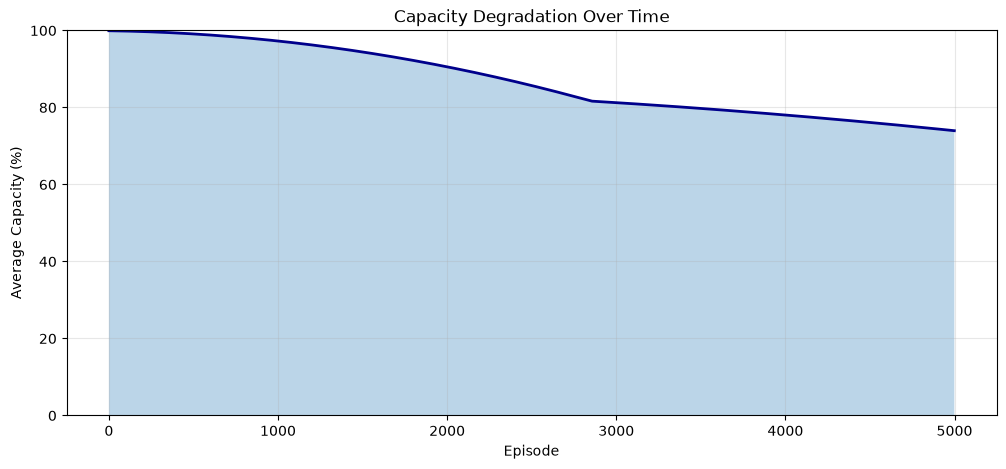

In [22]:
plt.figure(figsize=(12, 5))
plt.plot(capacity_timeline, linewidth=2, color="darkblue")
plt.fill_between(range(len(capacity_timeline)), capacity_timeline, alpha=0.3)
plt.xlabel("Episode")
plt.ylabel("Average Capacity (%)")
plt.title("Capacity Degradation Over Time")
plt.grid(True, alpha=0.3)
plt.ylim([0, 100])
plt.show()

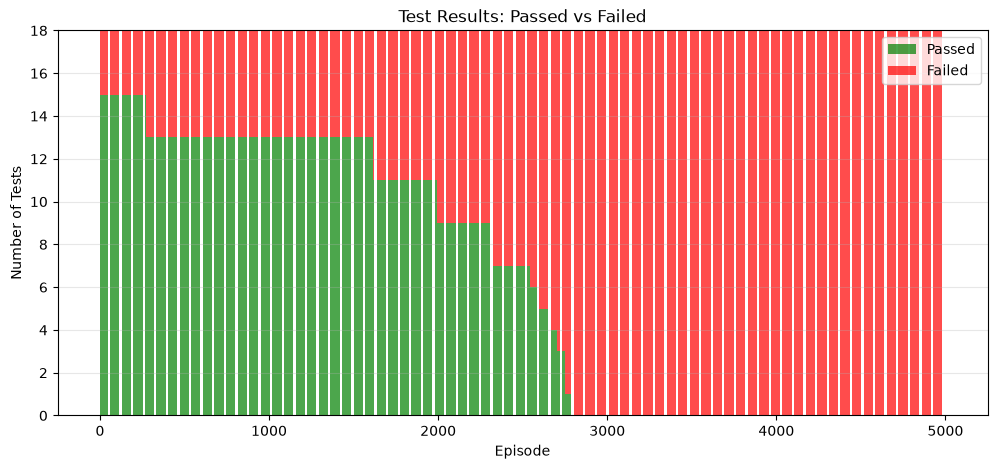

In [23]:
passed = pass_fail_timeline
failed = 18 - pass_fail_timeline

plt.figure(figsize=(12, 5))
plt.bar(range(len(passed)), passed, label="Passed", color="green", alpha=0.7)
plt.bar(range(len(failed)), failed, bottom=passed, label="Failed", color="red", alpha=0.7)
plt.xlabel("Episode")
plt.ylabel("Number of Tests")
plt.title("Test Results: Passed vs Failed")
plt.legend()
plt.ylim([0, 18])
plt.grid(True, alpha=0.3, axis="y")
plt.show()

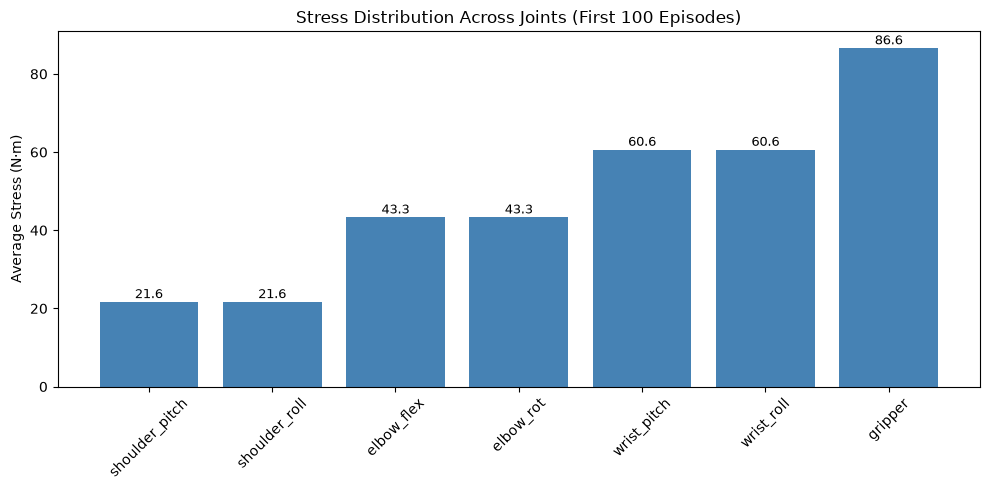

In [24]:
stress_per_joint = np.zeros(7)

for episode_id in range(min(100, len(wear_timeline))):
    episode_dir = OUTPUT_DIR / f"episode_{episode_id:05d}"
    with open(episode_dir / "metadata.json") as f:
        metadata = json.load(f)
    
    for joint_idx in range(7):
        stress_key = f"joint_{joint_idx}_{JOINT_NAMES[joint_idx]}"
        stress_per_joint[joint_idx] += metadata["stress_history"][stress_key]["avg_stress"]

stress_per_joint /= min(100, len(wear_timeline))

plt.figure(figsize=(10, 5))
bars = plt.bar(JOINT_NAMES, stress_per_joint, color="steelblue")
plt.ylabel("Average Stress (N·m)")
plt.title("Stress Distribution Across Joints (First 100 Episodes)")
for i, stress in enumerate(stress_per_joint):
    plt.text(i, stress + 1, f"{stress:.1f}", ha="center", fontsize=9)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
final_wear = wear_timeline[-1]
final_capacity = capacity_timeline[-1]
final_passed = pass_fail_timeline[-1]

print("=== FINAL STATE (Episode 5000) ===")
print()
print("Wear by joint:")
for joint, wear in zip(JOINT_NAMES, final_wear):
    status = "OK" if wear < 0.2 else "WARNING" if wear < 0.5 else "CRITICAL"
    print(f"  {joint:20} {wear:.3f} [{status}]")

print(f"\nAverage Capacity: {final_capacity:.1f}%")
print(f"Tests Passed: {final_passed}/18")
print(f"Tests Failed: {18 - final_passed}/18")

most_worn = np.argmax(final_wear)
print(f"\nMost Worn Joint: {JOINT_NAMES[most_worn]} (wear={final_wear[most_worn]:.3f})")

=== FINAL STATE (Episode 5000) ===

Wear by joint:
  shoulder_pitch       0.069 [OK]
  shoulder_roll        0.069 [OK]
  elbow_flex           0.254 [WARNING]
  elbow_rot            0.244 [WARNING]
  wrist_pitch          0.597 [CRITICAL]
  wrist_roll           0.577 [CRITICAL]
  gripper              1.000 [CRITICAL]

Average Capacity: 74.0%
Tests Passed: 0/18
Tests Failed: 18/18

Most Worn Joint: gripper (wear=1.000)
